# Flight Data ETL with the DataFrame API

Databricks free https://dbc-0b69ef93-5247.cloud.databricks.com/editor/notebooks/1515760616498474?o=7474657872577658

# 4.2 Demo - Flight Data ETL with the DataFrame API

This demonstration walks through common ETL operations using the flights dataset created during the required setup. We cover data loading, cleaning, transformation, and analysis using the DataFrame API.

## Learning Objectives

By the end of this demo, you will be able to:

* Implement common ETL operations using Spark DataFrames
* Handle data cleaning and type conversion under Spark 4 ANSI mode
* Create derived features through transformations

## Flight Data Processing Requirements

We are going to act on a typical ETL requirement: land a cleaned, enriched version of the raw flight data as a new table.

* **Source data:** the `flights` table in your `intro_spark` schema (synthetic flight information generated during setup, with intentionally messy values)
* **Target:** a table named `cleaned_and_enriched_flights` with this schema:

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `FlightDateTime` | `TIMESTAMP_NTZ` | Datetime of the flight, derived from the `Year`, `Month`, `DayofMonth`, and `DepTime` fields in the source data |
| `FlightNum` | `INT` | Flight number |
| `ElapsedTime` | `INT` | Difference between actual and scheduled elapsed time, derived from `ActualElapsedTime` and `CRSElapsedTime` |
| `ArrDelayCategory` | `STRING` | One of `On Time`, `Slight Delay`, `Moderate Delay`, `Severe Delay`, based on the value of `ArrDelay` |

---

## B. Data Loading and Inspection

First, let's load and inspect the flight data.

In [0]:
%python
# Tenta carregar o dataset de voos a partir do diretório padrão de exemplos públicos do Databricks
flights_df = spark.read.format("csv").option("header", "true").option("inferSchema", "true").load("/databricks-datasets/learning-spark-v2/flights/departuredelays.csv")

# Exibe uma amostra para confirmar
display(flights_df.limit(5))

date,delay,distance,origin,destination
1011245,6,602,ABE,ATL
1020600,-8,369,ABE,DTW
1021245,-2,602,ABE,ATL
1020605,-4,602,ABE,ATL
1031245,-4,602,ABE,ATL


In [0]:
%python
spark.sql("SHOW TABLES").display()

database,tableName,isTemporary
default,aula_spark_day_hour,false
default,baseline_features,false
default,baseline_features_29082026,false
default,batch_inference,false
default,customers,false
default,delta_table_wine06092026,false
default,diabetes_new,false
default,diabetes_patient_features_05092026,false
default,distributed_predictions_table_20062026,false
default,distributed_predictions_table_26092026_bkp,false


In [0]:
%python
# Classroom Setup
#%run ../Includes/Classroom-Setup-4

# Read the Flights Table
#flights_df = spark.read.table("flights")
#https://databricks-prod-cloudfront.cloud.databricks.com/public/4027ec902e239c93eaaa8714f173bcfc/3741049972324885/3065536941249190/4413065072037724/latest.html
# Display the loaded data preview
#display(flights_df.limit(5))

What to Observe

Several columns that should be numeric — DepTime, ActualElapsedTime, ArrDelay — arrived as strings. This is common with data exported from older systems, and cleaning it up is the core of this demo.

In [0]:
# página 4
from pyspark.sql.functions import col
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

# Schema explícito do dataset de voos (demo 4.2)
flights_schema = StructType([
    StructField("Year", IntegerType(), True),
    StructField("Month", IntegerType(), True),
    StructField("DayofMonth", IntegerType(), True),
    StructField("DepTime", StringType(), True),
    StructField("FlightNum", IntegerType(), True),
    StructField("UniqueCarrier", StringType(), True),
    StructField("CRSElapsedTime", IntegerType(), True),
    StructField("ActualElapsedTime", IntegerType(), True),
    StructField("ArrDelay", StringType(), True),
])

# O CSV do databricks-datasets que contém essas colunas é o dataset ASA airlines
# (o departuredelays.csv usado antes só tem date/delay/distance/origin/destination).
# Exclui voos cancelados e desviados: são eles que têm "NA" nas colunas de tempo,
# o que faria o cast para INT falhar no modo ANSI do Spark 4.
flights_df = (
    spark.read.format("csv")
    .option("header", "true")
    .load("/databricks-datasets/asa/small/small.csv")
    .filter((col("Cancelled") == "0") & (col("Diverted") == "0"))
    .select([col(f.name).cast(f.dataType).alias(f.name) for f in flights_schema.fields])
)

# Registra a view "flights" para as próximas células da demo
flights_df.createOrReplaceTempView("flights")

print("Total de voos:", flights_df.count())
display(flights_df.limit(5))

Total de voos: 196006


Year,Month,DayofMonth,DepTime,FlightNum,UniqueCarrier,CRSElapsedTime,ActualElapsedTime,ArrDelay
2002,12,31,1415,48,UA,297,283,-19
2002,12,13,2237,48,UA,324,334,17
2002,12,14,2227,48,UA,324,311,-16
2002,12,15,2226,48,UA,324,319,-9
2002,12,16,2224,48,UA,324,317,-13


In [0]:
#print the schema
flights_df.printSchema()

root
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayofMonth: integer (nullable = true)
 |-- DepTime: string (nullable = true)
 |-- FlightNum: integer (nullable = true)
 |-- UniqueCarrier: string (nullable = true)
 |-- CRSElapsedTime: integer (nullable = true)
 |-- ActualElapsedTime: integer (nullable = true)
 |-- ArrDelay: string (nullable = true)



In [0]:
#visually inspect a Subset of the Data
display(flights_df.limit(10))

Year,Month,DayofMonth,DepTime,FlightNum,UniqueCarrier,CRSElapsedTime,ActualElapsedTime,ArrDelay
2002,12,31,1415,48,UA,297,283,-19
2002,12,13,2237,48,UA,324,334,17
2002,12,14,2227,48,UA,324,311,-16
2002,12,15,2226,48,UA,324,319,-9
2002,12,16,2224,48,UA,324,317,-13
2002,12,17,2226,48,UA,324,337,9
2002,12,18,2233,48,UA,324,319,-2
2002,12,19,2254,48,UA,324,305,5
2002,12,20,2302,48,UA,324,316,24
2002,12,21,2315,48,UA,324,303,24


In [0]:
%python
# Select Only the Columns We Need
# Remember: filter early, filter often
flights_required_cols_df = flights_df.select(
    "Year",
    "Month",
    "DayofMonth",
    "DepTime",
    "FlightNum",
    "CRSElapsedTime",
    "ActualElapsedTime",
    "ArrDelay"
)

# Alternatively, we could have used the drop() method to remove the columns we didn't want

In [0]:
%python
# Count the Source Records
initial_count = flights_required_cols_df.count()

print(f"Source data has {initial_count} records")

Source data has 196006 records


## C. Analyzing Invalid Values

The string columns we intend to perform mathematical operations on (`ArrDelay`, `ActualElapsedTime`, `DepTime`) may contain nulls or invalid values such as `NA`[cite: 8].

> **ANSI Mode and Casting**
> 
> Spark 4 runs in ANSI SQL mode by default: `CAST('NA' AS INT)` raises an error instead of silently returning `NULL`. We therefore use `TRY_CAST`, which returns `NULL` for invalid values, letting us find and handle them deliberately[cite: 8].

In [0]:
%python
# Register a Temp View with Cast Columns
# Register the DataFrame as a temporary view with TRY_CAST columns for analysis
flights_required_cols_df.selectExpr(
    "Year",
    "Month",
    "DayofMonth",
    "TRY_CAST(DepTime AS INT) AS DepTime",
    "FlightNum",
    "TRY_CAST(ActualElapsedTime AS INT) AS ActualElapsedTime",
    "CRSElapsedTime",
    "TRY_CAST(ArrDelay AS INT) AS ArrDelay"
).createOrReplaceTempView("flights_temp")

In [0]:
%python
# Count Null Values with Spark SQL
# Use the COUNT_IF SQL function to count invalid (now null) values per column
invalid_counts_sql = spark.sql("""
    SELECT
        COUNT_IF(Year IS NULL) AS Null_Year_Count,
        COUNT_IF(Month IS NULL) AS Null_Month_Count,
        COUNT_IF(DayofMonth IS NULL) AS Null_DayofMonth_Count,
        COUNT_IF(DepTime IS NULL) AS Null_DepTime_Count,
        COUNT_IF(FlightNum IS NULL) AS Null_FlightNum_Count,
        COUNT_IF(ActualElapsedTime IS NULL) AS Null_ActualElapsedTime_Count,
        COUNT_IF(CRSElapsedTime IS NULL) AS Null_CRSElapsedTime_Count,
        COUNT_IF(ArrDelay IS NULL) AS Null_ArrDelay_Count
    FROM flights_temp
""")

display(invalid_counts_sql)

Null_Year_Count,Null_Month_Count,Null_DayofMonth_Count,Null_DepTime_Count,Null_FlightNum_Count,Null_ActualElapsedTime_Count,Null_CRSElapsedTime_Count,Null_ArrDelay_Count
0,0,0,0,0,0,0,0


## Comparing Spark SQL to DataFrame API Operations

Spark SQL queries and their equivalent operations in the DataFrame API are evaluated to the same physical plans. Let's prove this.

In [0]:
%python
# Count Null Values with the DataFrame API
# This is the equivalent of the preceding Spark SQL query using the DataFrame API
from pyspark.sql.functions import col, sum, when

# Make sure to work with the same temporary view that the SQL is using
flights_temp_df = spark.table("flights_temp")

invalid_counts_df = flights_temp_df.select(
    sum(when(col("Year").isNull(), 1).otherwise(0)).alias("Null_Year_Count"),
    sum(when(col("Month").isNull(), 1).otherwise(0)).alias("Null_Month_Count"),
    sum(when(col("DayofMonth").isNull(), 1).otherwise(0)).alias("Null_DayofMonth_Count"),
    sum(when(col("DepTime").isNull(), 1).otherwise(0)).alias("Null_DepTime_Count"),
    sum(when(col("FlightNum").isNull(), 1).otherwise(0)).alias("Null_FlightNum_Count"),
    sum(when(col("ActualElapsedTime").isNull(), 1).otherwise(0)).alias("Null_ActualElapsedTime_Count"),
    sum(when(col("CRSElapsedTime").isNull(), 1).otherwise(0)).alias("Null_CRSElapsedTime_Count"),
    sum(when(col("ArrDelay").isNull(), 1).otherwise(0)).alias("Null_ArrDelay_Count")
)

display(invalid_counts_df)

Null_Year_Count,Null_Month_Count,Null_DayofMonth_Count,Null_DepTime_Count,Null_FlightNum_Count,Null_ActualElapsedTime_Count,Null_CRSElapsedTime_Count,Null_ArrDelay_Count
0,0,0,0,0,0,0,0


In [0]:
%python
# Explain the DataFrame Version
invalid_counts_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonAgg(keys=[], functions=[finalmerge_sum(merge sum#10504L) AS sum(CASE WHEN (Year IS NULL) THEN 1 ELSE 0 END)#10495L, finalmerge_sum(merge sum#10506L) AS sum(CASE WHEN (Month IS NULL) THEN 1 ELSE 0 END)#10496L, finalmerge_sum(merge sum#10508L) AS sum(CASE WHEN (DayofMonth IS NULL) THEN 1 ELSE 0 END)#10497L, finalmerge_sum(merge sum#10510L) AS sum(CASE WHEN (DepTime IS NULL) THEN 1 ELSE 0 END)#10498L, finalmerge_sum(merge sum#10512L) AS sum(CASE WHEN (FlightNum IS NULL) THEN 1 ELSE 0 END)#10499L, finalmerge_sum(merge sum#10514L) AS sum(CASE WHEN (ActualElapsedTime IS NULL) THEN 1 ELSE 0 END)#10500L, finalmerge_sum(merge sum#10516L) AS sum(CASE WHEN (CRSElapsedTime IS NULL) THEN 1 ELSE 0 END)#10501L, finalmerge_sum(merge sum#10518L) AS sum(CASE WHEN (ArrDelay IS NULL) THEN 1 ELSE 0 END)#10502L])
         +- PhotonShuffleExchangeSource false
           

In [0]:
invalid_counts_sql.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonAgg(keys=[], functions=[finalmerge_count(merge count#10569L) AS count((IF((Year IS NOT NULL), NULL, (Year IS NULL))))#10560L, finalmerge_count(merge count#10571L) AS count((IF((Month IS NOT NULL), NULL, (Month IS NULL))))#10561L, finalmerge_count(merge count#10573L) AS count((IF((DayofMonth IS NOT NULL), NULL, (DayofMonth IS NULL))))#10562L, finalmerge_count(merge count#10575L) AS count((IF((DepTime IS NOT NULL), NULL, (DepTime IS NULL))))#10563L, finalmerge_count(merge count#10577L) AS count((IF((FlightNum IS NOT NULL), NULL, (FlightNum IS NULL))))#10564L, finalmerge_count(merge count#10579L) AS count((IF((ActualElapsedTime IS NOT NULL), NULL, (ActualElapsedTime IS NULL))))#10565L, finalmerge_count(merge count#10581L) AS count((IF((CRSElapsedTime IS NOT NULL), NULL, (CRSElapsedTime IS NULL))))#10566L, finalmerge_count(merge count#10583L) AS count(

What to Observe

Compare the two physical plans printed above — they are the same. Spark SQL and the DataFrame API are two front ends to the same Catalyst optimizer and execution engine, so you can choose whichever is clearer for the task at hand.

# D. Data Cleaning

In [0]:
%python
# Drop Rows with Null CRSElapsedTime
# To drop rows where any specified columns are null, use the na.drop DataFrame method
non_null_flights_df = flights_required_cols_df.na.drop(
    how="any",
    subset=["CRSElapsedTime"]
)

In [0]:
%python
# Remove Rows with Invalid Numeric Strings
from pyspark.sql.functions import col

# Keep only rows where the string columns hold valid integers
flights_with_valid_data_df = non_null_flights_df.filter(
    col("ArrDelay").try_cast("integer").isNotNull() &
    col("ActualElapsedTime").try_cast("integer").isNotNull() &
    col("DepTime").try_cast("integer").isNotNull()
)

In [0]:
%python
# Cast the String Columns to Integers
# Now that we know the columns contain only valid integer values, cast them
# from strings to integers (replacing the existing columns)
clean_flights_df = (flights_with_valid_data_df
    .withColumn("ArrDelay", col("ArrDelay").try_cast("integer"))
    .withColumn("ActualElapsedTime", col("ActualElapsedTime").try_cast("integer"))
)

clean_flights_df.printSchema()

root
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayofMonth: integer (nullable = true)
 |-- DepTime: string (nullable = true)
 |-- FlightNum: integer (nullable = true)
 |-- CRSElapsedTime: integer (nullable = true)
 |-- ActualElapsedTime: integer (nullable = true)
 |-- ArrDelay: integer (nullable = true)



## E. Data Enrichment

Now let's create the derived columns from the requirements: a proper flight timestamp, a delay category, and the elapsed time difference.

In [0]:
%python
# Derive the FlightDateTime Column
# Derive FlightDateTime from the Year, Month, DayofMonth, and DepTime columns,
# then drop the constituent columns
from pyspark.sql.functions import col, make_timestamp_ntz, lpad, substr, lit

flights_with_datetime_df = clean_flights_df.withColumn(
    "FlightDateTime",
    make_timestamp_ntz(
        col("Year"),
        col("Month"),
        col("DayofMonth"),
        lpad(col("DepTime"), 4, "0").substr(1, 2).try_cast("integer"),
        lpad(col("DepTime"), 4, "0").substr(3, 2).try_cast("integer"),
        lit(0)
    )
).drop("Year", "Month", "DayofMonth", "DepTime")

display(flights_with_datetime_df.limit(10))

FlightNum,CRSElapsedTime,ActualElapsedTime,ArrDelay,FlightDateTime
48,297,283,-19,2002-12-31T14:15:00.000
48,324,334,17,2002-12-13T22:37:00.000
48,324,311,-16,2002-12-14T22:27:00.000
48,324,319,-9,2002-12-15T22:26:00.000
48,324,317,-13,2002-12-16T22:24:00.000
48,324,337,9,2002-12-17T22:26:00.000
48,324,319,-2,2002-12-18T22:33:00.000
48,324,305,5,2002-12-19T22:54:00.000
48,324,316,24,2002-12-20T23:02:00.000
48,324,303,24,2002-12-21T23:15:00.000


In [0]:
%python
# Categorize Arrival Delays
# Categorize the ArrDelay column into: On Time, Slight Delay, Moderate Delay, Severe Delay
from pyspark.sql.functions import when, col

enriched_flights_df = (
    flights_with_datetime_df
    .withColumn(
        "ArrDelayCategory",
        when(col("ArrDelay") <= 0, "On Time")
        .when(col("ArrDelay") <= 15, "Slight Delay")
        .when(col("ArrDelay") <= 60, "Moderate Delay")
        .otherwise("Severe Delay")
    )
    .drop("ArrDelay")
)

display(enriched_flights_df.limit(10))

FlightNum,CRSElapsedTime,ActualElapsedTime,FlightDateTime,ArrDelayCategory
48,297,283,2002-12-31T14:15:00.000,On Time
48,324,334,2002-12-13T22:37:00.000,Moderate Delay
48,324,311,2002-12-14T22:27:00.000,On Time
48,324,319,2002-12-15T22:26:00.000,On Time
48,324,317,2002-12-16T22:24:00.000,On Time
48,324,337,2002-12-17T22:26:00.000,Slight Delay
48,324,319,2002-12-18T22:33:00.000,On Time
48,324,305,2002-12-19T22:54:00.000,Slight Delay
48,324,316,2002-12-20T23:02:00.000,Moderate Delay
48,324,303,2002-12-21T23:15:00.000,Moderate Delay


In [0]:
%python
# Derive the ElapsedTimeDiff Column
# Derive ElapsedTimeDiff from the ActualElapsedTime and CRSElapsedTime columns
from pyspark.sql.functions import col

enriched_flights_df = enriched_flights_df.withColumn(
    "ElapsedTimeDiff", col("ActualElapsedTime") - col("CRSElapsedTime")
).drop("ActualElapsedTime", "CRSElapsedTime")

display(enriched_flights_df.select("FlightNum", "FlightDateTime", "ElapsedTimeDiff").limit(10))

FlightNum,FlightDateTime,ElapsedTimeDiff
48,2002-12-31T14:15:00.000,-14
48,2002-12-13T22:37:00.000,10
48,2002-12-14T22:27:00.000,-13
48,2002-12-15T22:26:00.000,-5
48,2002-12-16T22:24:00.000,-7
48,2002-12-17T22:26:00.000,13
48,2002-12-18T22:33:00.000,-5
48,2002-12-19T22:54:00.000,-19
48,2002-12-20T23:02:00.000,-8
48,2002-12-21T23:15:00.000,-21


## Visualize the Delay Categories

PySpark in Spark 4 includes native plotting: call `df.plot` directly on a DataFrame (backed by plotly) without converting to pandas first.

In [0]:
delay_counts_df = enriched_flights_df.groupBy("ArrDelayCategory").count()

In [0]:
# Plot Delay Categories with Native Plotting
# Aggregate, then plot directly from the PySpark DataFrame (new in Spark 4)

In [0]:
delay_counts_df.show()

+----------------+------+
|ArrDelayCategory| count|
+----------------+------+
|  Moderate Delay| 26757|
|    Severe Delay| 10195|
|    Slight Delay| 46137|
|         On Time|112917|
+----------------+------+



In [0]:
%pip install plotly

#delay_counts_df = enriched_flights_df.groupBy("ArrDelayCategory").count()

delay_counts_df.plot.bar(x="ArrDelayCategory", y="count")

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


<!doctype html>

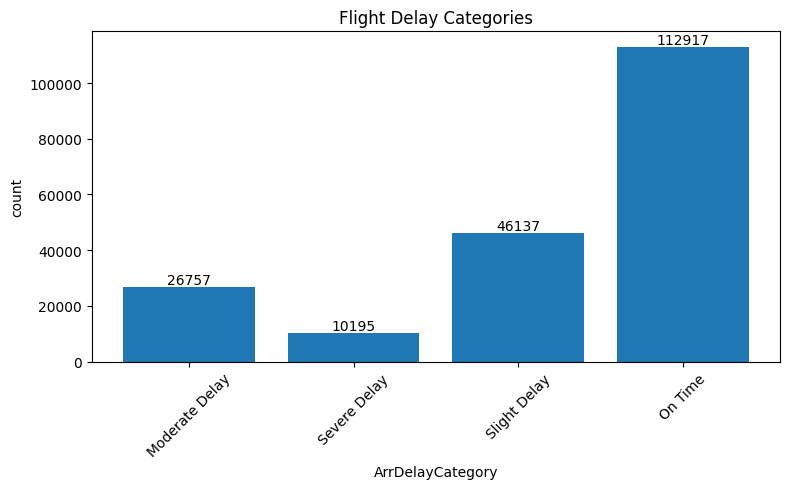

In [0]:
import matplotlib.pyplot as plt

# Collect the data to the driver for matplotlib plotting
pdf = delay_counts_df.toPandas()

plt.figure(figsize=(8, 5))
bars = plt.bar(pdf["ArrDelayCategory"], pdf["count"])
plt.xlabel("ArrDelayCategory")
plt.ylabel("count")
plt.title("Flight Delay Categories")
plt.xticks(rotation=45)

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

> **Other Visualization Options**
> 
> You can also use the `+ -> Visualization` option in any `display()` result, or ask the Databricks Assistant to generate chart code for you.

## F. Analyzing Delays with Different Column References

Let's analyze our delay categories while exercising the column referencing approaches from the lecture.

In [0]:
%python
# Reference Columns Directly
# Direct string references
display(enriched_flights_df.select("FlightNum", "ArrDelayCategory").limit(100))

FlightNum,ArrDelayCategory
48,On Time
48,Moderate Delay
48,On Time
48,On Time
48,On Time
48,Slight Delay
48,On Time
48,Slight Delay
48,Moderate Delay
48,Moderate Delay


In [0]:
%python
# Reference Columns with Column Objects
from pyspark.sql.functions import col

# Column objects support methods like alias()
display(
    enriched_flights_df
    .select(col("FlightNum").alias("flight_number"), col("ArrDelayCategory"))
    .limit(10)
)

flight_number,ArrDelayCategory
48,On Time
48,Moderate Delay
48,On Time
48,On Time
48,On Time
48,Slight Delay
48,On Time
48,Slight Delay
48,Moderate Delay
48,Moderate Delay


In [0]:
%python
# Reference Columns with String Expressions
# selectExpr accepts SQL expressions
display(
    enriched_flights_df
    .selectExpr("FlightNum", "ElapsedTimeDiff", "ElapsedTimeDiff > 0 AS LongerThanScheduled")
    .limit(100)
)

FlightNum,ElapsedTimeDiff,LongerThanScheduled
48,-14,false
48,10,true
48,-13,false
48,-5,false
48,-7,false
48,13,true
48,-5,false
48,-19,false
48,-8,false
48,-21,false


## G. Working with UDFs

Let's use a vectorized pandas UDF to calculate the z-score (standard deviations from the mean) of the elapsed time difference for each flight.

In [0]:
%python
# Apply a Vectorized Pandas UDF
from pyspark.sql.functions import pandas_udf

# Pandas UDF (vectorized) - operates on batches of rows as pandas Series
@pandas_udf("double")
def normalized_diff(diff_series):
    return (diff_series - diff_series.mean()) / diff_series.std()

udf_example_df = enriched_flights_df.withColumn(
    "diff_normalized", normalized_diff("ElapsedTimeDiff")
)

display(udf_example_df.limit(100))

# Note: in practice, prefer built-in functions over UDFs when possible

FlightNum,FlightDateTime,ArrDelayCategory,ElapsedTimeDiff,diff_normalized
48,2002-12-31T14:15:00.000,On Time,-14,-0.5056946177483806
48,2002-12-13T22:37:00.000,Moderate Delay,10,0.9391471472469927
48,2002-12-14T22:27:00.000,On Time,-13,-0.44549287754024014
48,2002-12-15T22:26:00.000,On Time,-5,0.03612104412488431
48,2002-12-16T22:24:00.000,On Time,-7,-0.0842824362913968
48,2002-12-17T22:26:00.000,Slight Delay,13,1.1197523678714143
48,2002-12-18T22:33:00.000,On Time,-5,0.03612104412488431
48,2002-12-19T22:54:00.000,Slight Delay,-19,-0.8067033187890834
48,2002-12-20T23:02:00.000,Moderate Delay,-8,-0.14448417649953735
48,2002-12-21T23:15:00.000,Moderate Delay,-21,-0.9271067992053645


## H. Putting It All Together

Let's combine everything into a single chained operation that reads from the source, cleans, enriches, and saves to a new target table (overwriting any existing data).

In [0]:
%python
# Drop the Target Table If It Exists
spark.sql("DROP TABLE IF EXISTS cleaned_enriched_flights")

DataFrame[]

In [0]:
%python
# Run the Full ETL Pipeline
from pyspark.sql.functions import col, make_timestamp_ntz, lpad, substr, lit, when, pandas_udf

@pandas_udf("double")
def normalized_diff(diff_series):
    return (diff_series - diff_series.mean()) / diff_series.std()


flights_df = (
    spark.read.format("csv")
    .option("header", "true")
    .load("/databricks-datasets/asa/small/small.csv")
    .filter((col("Cancelled") == "0") & (col("Diverted") == "0"))
    .select([col(f.name).cast(f.dataType).alias(f.name) for f in flights_schema.fields])
)

# Registra a view "flights" para as próximas células da demo
flights_df.createOrReplaceTempView("flights")



#(spark.read.table("flights")
# Project and convert the columns we need
(flights_df.selectExpr(
        "Year",
        "Month",
        "DayofMonth",
        "TRY_CAST(DepTime AS INT) AS DepTime",
        "FlightNum",
        "TRY_CAST(ActualElapsedTime AS INT) AS ActualElapsedTime",
        "CRSElapsedTime",
        "TRY_CAST(ArrDelay AS INT) AS ArrDelay"
    )
    # Drop any rows with invalid or missing values
    .na.drop()
    .filter(col("DepTime") < 2400)
    # Derive the flight timestamp, then drop its constituent columns
    .withColumn(
        "FlightDateTime",
        make_timestamp_ntz(
            col("Year"),
            col("Month"),
            col("DayofMonth"),
            lpad(col("DepTime"), 4, "0").substr(1, 2).try_cast("integer"),
            lpad(col("DepTime"), 4, "0").substr(3, 2).try_cast("integer"),
            lit(0)
        )
    )
    .drop("Year", "Month", "DayofMonth", "DepTime")
    # Derive the elapsed time difference
    .withColumn("ElapsedTimeDiff", col("ActualElapsedTime") - col("CRSElapsedTime"))
    .drop("ActualElapsedTime", "CRSElapsedTime")
    # Categorize arrival delays
    .withColumn(
        "ArrDelayCategory",
        when(col("ArrDelay") <= 0, "On Time")
        .when(col("ArrDelay") <= 15, "Slight Delay")
        .when(col("ArrDelay") <= 60, "Moderate Delay")
        .otherwise("Severe Delay")
    )
    .drop("ArrDelay")
    # Optional normalized diff
    .withColumn("diff_normalized", normalized_diff("ElapsedTimeDiff"))
    # Write to target table
    .write
    .mode("overwrite")
    .saveAsTable("cleaned_enriched_flights")
)

In [0]:
%sql
-- Query the Target Table
SELECT * FROM cleaned_enriched_flights LIMIT 10;

FlightNum,FlightDateTime,ElapsedTimeDiff,ArrDelayCategory,diff_normalized
48,2002-12-31T14:15:00.000,-14,On Time,-0.6623239811372277
48,2002-12-13T22:37:00.000,10,Moderate Delay,0.8623921493991032
48,2002-12-14T22:27:00.000,-13,On Time,-0.5987941423648806
48,2002-12-15T22:26:00.000,-5,On Time,-0.09055543218610358
48,2002-12-16T22:24:00.000,-7,On Time,-0.2176151097307978
48,2002-12-17T22:26:00.000,13,Slight Delay,1.0529816657161446
48,2002-12-18T22:33:00.000,-5,On Time,-0.09055543218610358
48,2002-12-19T22:54:00.000,-19,Slight Delay,-0.9799731749989633
48,2002-12-20T23:02:00.000,-8,Moderate Delay,-0.2811449485031449
48,2002-12-21T23:15:00.000,-21,Moderate Delay,-1.1070328525436575


## Key Takeaways

### Data cleaning best practices:
* Validate and clean data types early, using `try_cast()` under Spark 4 ANSI mode
* Handle missing values appropriately
* Document cleaning assumptions

### Data enrichment:
* Create meaningful derived columns driven by business requirements
* Use built-in functions where possible, and user defined functions where necessary

### Pipeline composition:
* Because transformations are lazy and return new DataFrames, an entire pipeline can be expressed as one readable chain ending in a single write action